# Phương pháp 4: Rolling & Expanding Window Forecasting (Walk-Forward Backtesting)

**Đồ án IS403 – Phân tích dữ liệu kinh doanh (Mở rộng nghiên cứu Chen et al., PLOS ONE 2023)**  
**Phụ trách thực nghiệm:** Quân

## 1. Mục tiêu nghiên cứu & Cơ sở lý thuyết

Trong tài chính và chuỗi thời gian hàng hóa (như giá đồng tương lai COMEX `HG=F`), mối quan hệ giữa giá đồng và các biến kinh tế vĩ mô (WTI, Vàng, Bạc) **không cố định theo thời gian** (*non-stationarity / concept drift*). Mô hình tĩnh (**Static Forecasting**) chỉ huấn luyện một lần trên quá khứ và giữ nguyên trọng số suốt giai đoạn kiểm thử dài (2024–2026) có nguy cơ suy giảm độ chính xác khi thị trường bước vào vùng giá hoặc chế độ biến động mới.

Để cô lập tác động của **chiến lược cập nhật dữ liệu (Updating Policy)** mà không thay đổi kiến trúc mạng, notebook này cố định kiến trúc **2-layer LSTM** (đã tối ưu bởi SA từ baseline của nhóm) và đối chiếu 5 chiến lược dự báo trên cùng một tập kiểm thử:

1. **`naive_persistence`**: $\hat{y}_t = y_{t-1}$ (mốc cơ sở bước ngẫu nhiên - Random Walk Baseline).
2. **`static_train_only`**: Huấn luyện & fit `MinMaxScaler` 1 lần trên tập Train (`[0, fit_end)`, 2006–2022), đóng băng qua suốt Validation và Test (tái hiện đúng thiết lập của baseline `copper-lstm-sa_1311.ipynb`).
3. **`static_train_val`**: Huấn luyện & fit `MinMaxScaler` 1 lần trên toàn bộ dữ liệu trước Test (`[0, test_start)`, 2006–2024), đóng băng suốt tập Test. Giúp tách bạch ảnh hưởng của *độ mới dữ liệu trước khi test* khỏi *việc tái huấn luyện định kỳ trong khi test*.
4. **`expanding_window`**: Walk-forward retraining tại các mốc $t_k = T_{\text{start}} + k \cdot S$ sử dụng **toàn bộ lịch sử tích lũy** `[0, t_k)`. Cho phép giữ toàn bộ ký ức dài hạn nhưng có thể phản ứng chậm với chế độ thị trường mới.
5. **`rolling_window`**: Walk-forward retraining tại các mốc $t_k$ chỉ sử dụng **cửa sổ trượt có độ dài cố định** $W$ phiên gần nhất `[max(0, t_k - W), t_k)`. Vừa cập nhật trọng số mô hình vừa cập nhật biên chuẩn hóa `MinMaxScaler` theo vùng giá hiện hành.

## 2. Quy chuẩn thực nghiệm & Cơ chế chống rò rỉ dữ liệu (No Data Leakage)

| Thành phần | Baseline (`copper-lstm-sa_1311.ipynb`) | Notebook Phương pháp 4 (Quân) |
|---|---|---|
| Dữ liệu | `copper_8_indicators_2006_2026.csv` (5,231 phiên) | Cùng dữ liệu, kiểm định toàn vẹn ngày & NaN |
| Chia dữ liệu | `ratios = [0.90, 0.925, 0.95]`, `val_frac = 0.10` | `ratio = 0.90` là mốc chính; kiểm tra chéo cả `0.925, 0.95` |
| Biến đầu vào | `FEATURES_3 = [WTI, Gold, Silver]` | Thực nghiệm song song `FEATURES_4 = [Copper, WTI, Gold, Silver]` & `FEATURES_3` |
| Lookback / Horizon | `LOOKBACK = 22`, Next-day close (`H = 1`) | Giữ nguyên `LOOKBACK = 22`, `HORIZON = 1` |
| Kiến trúc cố định | 2-layer LSTM + Dense(32, ReLU) + Dropout(0.2) + Dense(1) | Giữ nguyên kiến trúc, khóa bộ tham số SA (`9/37, lr=4.03e-4`) |
| MinMaxScaler | Fit 1 lần trên `train` | **Walk-forward:** Fit lại hoàn toàn trên `[fit_start, origin)` tại mỗi bước $t_k$ |
| Chọn chính sách | Không có | **Phase 1:** Chọn $(W^*, S^*, \text{update\_mode}^*)$ chỉ trên tập **Validation** |
| Thống kê & Đánh giá | MSE, RMSE, MAE, R² | Bổ sung **MASE**, phân tích theo **3 giai đoạn thị trường**, và kiểm định **Diebold-Mariano (DM)** |

## 3. Cấu hình môi trường, chế độ chạy & Khóa Seed

* Chọn `MODE = "QUICK_MODE"` để chạy thử nghiệm kiểm tra luồng nhanh (~1–2 phút).
* Chọn `MODE = "FULL_RESEARCH_MODE"` để chạy toàn bộ thực nghiệm đầy đủ trên Kaggle GPU cho báo cáo cuối kỳ.

In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler

# --- Chế độ thực nghiệm ---
MODE = "FULL_RESEARCH_MODE"  # Đổi thành "QUICK_MODE" nếu muốn chạy thử nhanh

SEED = 42
LOOKBACK = 22
HORIZON = 1
RATIOS = [0.90, 0.925, 0.95]
PRIMARY_RATIO = 0.90
VALIDATION_FRACTION = 0.10

# So sánh cả 4 biến (có giá đồng trễ theo Fig. 12 & Proposal) và 3 biến ngoại sinh (như notebook baseline)
FEATURES_4 = ["Copper", "WTI", "Gold", "Silver"]
FEATURES_3 = ["WTI", "Gold", "Silver"]
CANDIDATES = ["Dow_Jones", "Nasdaq", "Dollar_Index", "TBill_10Y", "Gold", "Silver", "WTI", "Copper_Volume"]

# Bộ siêu tham số cố định từ kết quả SA tốt nhất của nhóm (new_sa_lstm)
NEW_SA_CONFIG = {"lstm_units_1": 9, "lstm_units_2": 37, "learning_rate": 0.00040267575055105107}
PAPER_CONFIG = {"lstm_units_1": 39, "lstm_units_2": 111, "learning_rate": 5e-5}
VANILLA_CONFIG = {"lstm_units_1": 32, "lstm_units_2": 32, "learning_rate": 1e-3}

ACTIVE_HP = NEW_SA_CONFIG
BATCH_SIZE = 64
DROPOUT = 0.2
DENSE_UNITS = 32

MODES = {
    "QUICK_MODE": {
        "max_rows": 1500,
        "base_epochs": 5,
        "cold_epochs": 4,
        "warm_epochs": 2,
        "val_windows": [252, 504],
        "val_strides": [40],
        "val_update_modes": ["cold_start", "warm_start"],
        "ablation_windows": [252, 504],
        "ablation_strides": [20, 40],
        "run_cross_ratio": False,
    },
    "FULL_RESEARCH_MODE": {
        "max_rows": None,
        "base_epochs": 60,
        "cold_epochs": 30,
        "warm_epochs": 12,
        "val_windows": [252, 504, 1008],
        "val_strides": [20, 40],
        "val_update_modes": ["cold_start", "warm_start"],
        "ablation_windows": [252, 504, 1008],
        "ablation_strides": [10, 20, 40, 60],
        "run_cross_ratio": True,
    },
}

if MODE not in MODES:
    raise ValueError(f"Unsupported MODE: {MODE}")
CFG = MODES[MODE]

def resolve_data_path() -> Path:
    candidates = [
        Path("/kaggle/input/datasets/lancelot71000/copper-8-indicators-2006-2026/copper_8_indicators_2006_2026.csv"),
        Path("/kaggle/input/copper-8-indicators-2006-2026/copper_8_indicators_2006_2026.csv"),
        Path("../copper_8_indicators_2006_2026.csv"),
        Path("./copper_8_indicators_2006_2026.csv"),
    ]
    for p in candidates:
        if p.is_file():
            return p.resolve()

    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        exact = sorted(kaggle_input.rglob("copper_8_indicators_2006_2026.csv"))
        if exact:
            return exact[0].resolve()
        all_csvs = sorted(kaggle_input.rglob("*.csv"))
        copper_csvs = [p for p in all_csvs if "copper" in p.name.lower()]
        if copper_csvs:
            return copper_csvs[0].resolve()
        if len(all_csvs) == 1:
            return all_csvs[0].resolve()
        found_str = [str(p) for p in all_csvs] if all_csvs else [str(p) for p in kaggle_input.rglob("*")]
        raise FileNotFoundError(
            "Không tìm thấy copper_8_indicators_2006_2026.csv trong /kaggle/input! "
            f"Hãy bấm '+ Add Input' hoặc 'Upload' ở cột phải để gắn file CSV. "
            f"Hiện có trong /kaggle/input: {found_str}"
        )

    raise FileNotFoundError(f"Không tìm thấy copper_8_indicators_2006_2026.csv tại các vị trí: {candidates}")

def resolve_output_dir() -> Path:
    root = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./output_rolling_expanding")
    out = root / "rolling_expanding_quan" / MODE.lower()
    out.mkdir(parents=True, exist_ok=True)
    return out

def set_global_seed(seed: int = SEED) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

DATA_PATH = resolve_data_path()
OUT_DIR = resolve_output_dir()
set_global_seed(SEED)
plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print(f"MODE      : {MODE}")
print(f"DATA_PATH : {DATA_PATH}")
print(f"OUT_DIR   : {OUT_DIR}")
print(f"TF Version: {tf.__version__} | GPUs: {[g.name for g in tf.config.list_physical_devices('GPU')]}")

MODE      : FULL_RESEARCH_MODE
DATA_PATH : /kaggle/input/datasets/laq2006/copperdata/copper_8_indicators_2006_2026.csv
OUT_DIR   : /kaggle/working/rolling_expanding_quan/full_research_mode
TF Version: 2.21.0 | GPUs: ['/physical_device:GPU:0', '/physical_device:GPU:1']


## 4. Tải dữ liệu, kiểm định chất lượng & Phân tích biến động theo giai đoạn

Kiểm tra tính liên tục theo thời gian, giá trị khuyết/vô hạn, trùng lặp ngày và trực quan hóa độ biến động lăn 60 ngày (`Rolling 60-day Volatility`) để chứng minh hiện tượng thay đổi cấu trúc thị trường (regime shift) giai đoạn 2006–2026.

Tổng số phiên hoàn chỉnh: 5231 (2006-01-03 -> 2026-10-29)
Primary Split (ratio=0.9):
  - Train     : 0 -> 4235 (2006-01-03 -> 2022-11-09) | 4236 phiên
  - Validation: 4236 -> 4706 (2022-11-10 -> 2024-09-26) | 471 phiên
  - Test      : 4707 -> 5230 (2024-09-27 -> 2026-10-29) | 524 phiên


,column,missing_raw,rows_used,first_date,last_date,min,max,mean,std
0,Copper,0,5231,2006-01-03,2026-10-29,1.247500,6.803500,3.435309,0.948303
1,Dow_Jones,0,5231,2006-01-03,2026-10-29,6547.049805,54349.121094,22816.577766,11788.081096
2,Nasdaq,0,5231,2006-01-03,2026-10-29,1268.640015,27599.789062,7898.760534,6422.009662
3,Dollar_Index,0,5231,2006-01-03,2026-10-29,71.330002,114.110001,90.790715,9.803972
4,TBill_10Y,0,5231,2006-01-03,2026-10-29,0.499000,5.311000,2.962773,1.147719
5,Gold,0,5231,2006-01-03,2026-10-29,526.299988,5318.399902,1611.907073,864.197585
6,Silver,0,5231,2006-01-03,2026-10-29,8.790000,115.080002,23.244733,12.839806
7,WTI,0,5231,2006-01-03,2026-10-29,-37.630001,145.289993,72.783332,21.147905
8,Copper_Volume,0,5231,2006-01-03,2026-10-29,0.000000,79408.000000,1451.324412,5630.006639


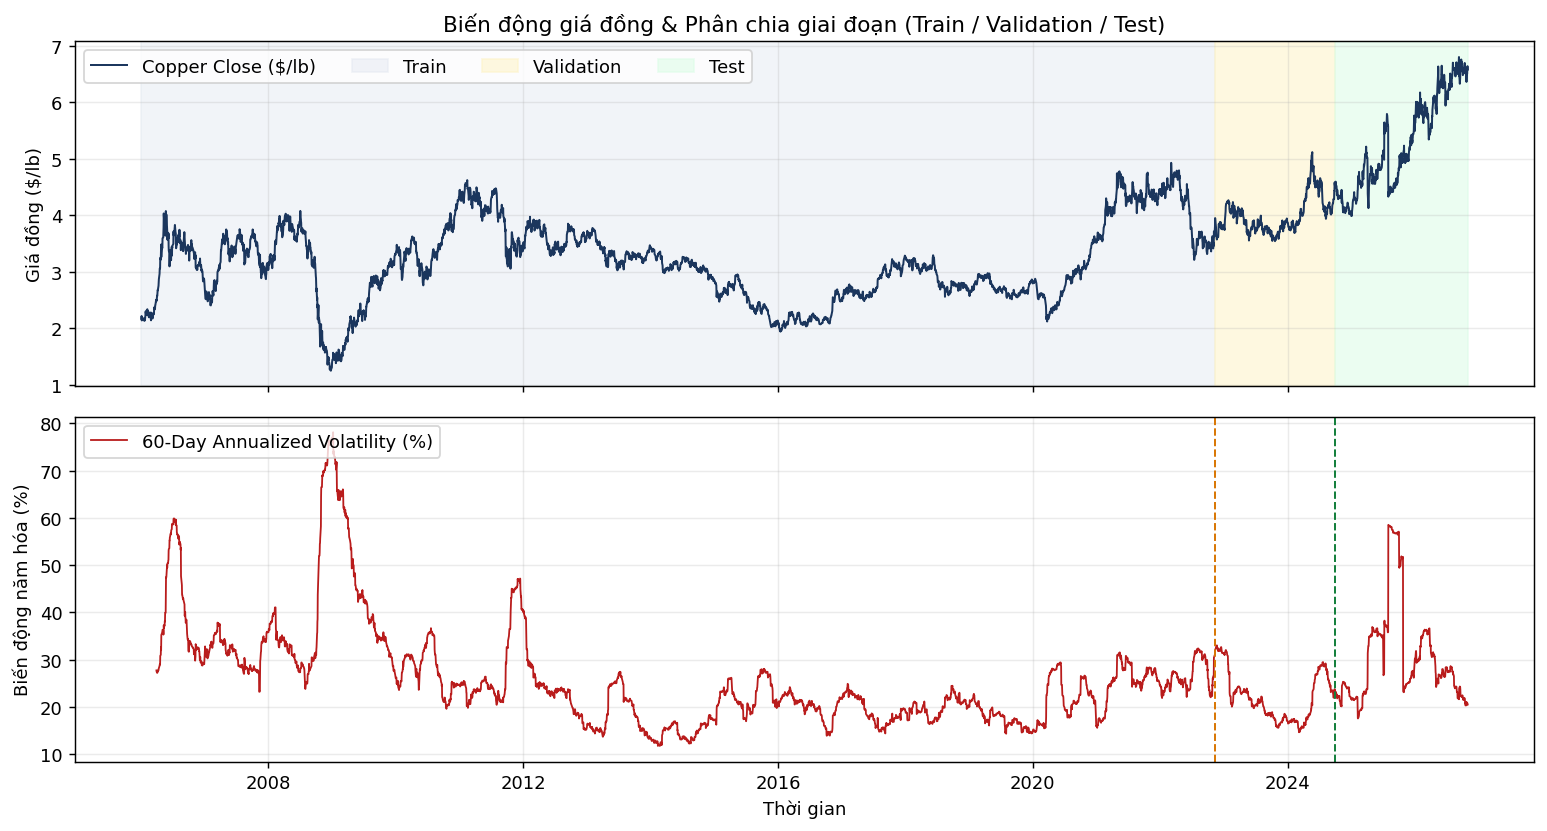

In [2]:
def load_and_audit_data(path: Path, out_dir: Path, max_rows: int | None = None):
    source = pd.read_csv(path)
    required = ["Date", "Copper"] + CANDIDATES
    missing_cols = sorted(set(required) - set(source.columns))
    if missing_cols:
        raise ValueError(f"Thiếu các cột bắt buộc: {missing_cols}")

    dates = pd.to_datetime(source["Date"], errors="coerce")
    invalid_dates = int(dates.isna().sum())
    dup_dates = int(dates.duplicated().sum())
    if invalid_dates > 0 or dup_dates > 0:
        raise ValueError(f"Dữ liệu có {invalid_dates} ngày lỗi và {dup_dates} ngày trùng lặp.")

    numeric = source[["Copper"] + CANDIDATES].apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    data = numeric.copy()
    data.insert(0, "Date", dates)
    data = data.sort_values("Date").dropna().set_index("Date")
    if max_rows is not None:
        data = data.tail(max_rows).copy()

    assert data.index.is_unique and data.index.is_monotonic_increasing, "Chuỗi thời gian không hợp lệ."
    assert np.isfinite(data.to_numpy()).all(), "Dữ liệu sau làm sạch vẫn chứa NaN/Inf."

    quality = pd.DataFrame([{
        "column": col,
        "missing_raw": int(numeric[col].isna().sum()),
        "rows_used": len(data),
        "first_date": str(data.index.min().date()),
        "last_date": str(data.index.max().date()),
        "min": float(data[col].min()),
        "max": float(data[col].max()),
        "mean": float(data[col].mean()),
        "std": float(data[col].std()),
    } for col in ["Copper"] + CANDIDATES])
    quality.to_csv(out_dir / "data_quality_audit.csv", index=False)
    return data, quality

def boundaries(n: int, ratio: float = PRIMARY_RATIO, val_fraction: float = VALIDATION_FRACTION):
    test_start = int(n * ratio)
    val_start = int(test_start * (1 - val_fraction))
    if not (0 < val_start < test_start < n):
        raise ValueError(f"Khoảng chia không hợp lệ: val_start={val_start}, test_start={test_start}, n={n}")
    return val_start, test_start

data, quality_df = load_and_audit_data(DATA_PATH, OUT_DIR, CFG["max_rows"])
fit_end_primary, test_start_primary = boundaries(len(data), PRIMARY_RATIO, VALIDATION_FRACTION)

print(f"Tổng số phiên hoàn chỉnh: {len(data)} ({data.index.min().date()} -> {data.index.max().date()})")
print(f"Primary Split (ratio={PRIMARY_RATIO}):")
print(f"  - Train     : 0 -> {fit_end_primary-1} ({data.index[0].date()} -> {data.index[fit_end_primary-1].date()}) | {fit_end_primary} phiên")
print(f"  - Validation: {fit_end_primary} -> {test_start_primary-1} ({data.index[fit_end_primary].date()} -> {data.index[test_start_primary-1].date()}) | {test_start_primary - fit_end_primary} phiên")
print(f"  - Test      : {test_start_primary} -> {len(data)-1} ({data.index[test_start_primary].date()} -> {data.index[-1].date()}) | {len(data) - test_start_primary} phiên")
display(quality_df)

# Biểu đồ 1: Giá đồng 2006-2026 & Biến động lăn (Chứng minh sự dịch chuyển phân phối theo thời gian)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(data.index, data["Copper"], color="#1B365D", linewidth=1.1, label="Copper Close ($/lb)")
axes[0].axvspan(data.index[0], data.index[fit_end_primary - 1], color="#E2E8F0", alpha=0.45, label="Train")
axes[0].axvspan(data.index[fit_end_primary], data.index[test_start_primary - 1], color="#FEF3C7", alpha=0.55, label="Validation")
axes[0].axvspan(data.index[test_start_primary], data.index[-1], color="#DCFCE7", alpha=0.55, label="Test")
axes[0].set_ylabel("Giá đồng ($/lb)")
axes[0].set_title("Biến động giá đồng & Phân chia giai đoạn (Train / Validation / Test)")
axes[0].legend(loc="upper left", ncol=4)

roll_vol = data["Copper"].pct_change().rolling(60).std() * np.sqrt(252) * 100
axes[1].plot(data.index, roll_vol, color="#B91C1C", linewidth=1.0, label="60-Day Annualized Volatility (%)")
axes[1].axvline(data.index[fit_end_primary], color="#D97706", linestyle="--", linewidth=1.1)
axes[1].axvline(data.index[test_start_primary], color="#15803D", linestyle="--", linewidth=1.1)
axes[1].set_ylabel("Biến động năm hóa (%)")
axes[1].set_xlabel("Thời gian")
axes[1].legend(loc="upper left")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig1_copper_regimes_volatility.png", dpi=150)
plt.show()

## 5. Bộ máy tạo cửa sổ trượt & Kiểm tra tính toàn vẹn chống rò rỉ dữ liệu

Mỗi lần tái huấn luyện tại mốc nguồn `origin = t_k`:
1. Xác định đoạn huấn luyện `[fit_start, origin)`:
   * **Expanding Window**: `fit_start = 0`
   * **Rolling Window**: `fit_start = max(0, origin - window_size)`
2. Khớp (`.fit()`) bộ chuẩn hóa `MinMaxScaler` **duy nhất trên `data.iloc[fit_start:origin]`** — tuyệt đối không dùng min/max của đoạn tương lai `[origin, block_end)`.
3. Tạo mẫu huấn luyện `(X_train, y_train)` có mục tiêu nằm trong `[fit_start + lookback, origin)` và mẫu dự báo `(X_eval, y_eval)` có mục tiêu nằm trong `[origin, block_end)` (với input `[t - lookback, ..., t - 1]`).

In [3]:
def make_windows(x_scaled: np.ndarray, y_scaled: np.ndarray, dates: pd.DatetimeIndex,
                 start: int, end: int, lookback: int = LOOKBACK):
    if start < lookback or end <= start:
        raise ValueError(f"Khoảng cửa sổ không hợp lệ: start={start}, end={end}, lookback={lookback}")
    X = np.stack([x_scaled[t - lookback:t] for t in range(start, end)]).astype("float32")
    y = y_scaled[start:end].astype("float32")
    target_dates = dates[start:end]
    return X, y, target_dates

def make_walk_forward_fold(
    data: pd.DataFrame,
    fit_start: int,
    origin: int,
    block_end: int,
    features: list[str],
    lookback: int = LOOKBACK,
):
    """Tạo 1 bước Walk-Forward hoàn toàn không rò rỉ dữ liệu."""
    assert 0 <= fit_start < origin < block_end <= len(data), "Thứ tự chỉ số không hợp lệ."
    assert origin - fit_start > lookback + 10, "Cửa sổ huấn luyện quá ngắn so với lookback."

    fit_df = data.iloc[fit_start:origin]
    x_scaler = MinMaxScaler().fit(fit_df[features])
    y_scaler = MinMaxScaler().fit(fit_df[["Copper"]])

    # Để tạo cửa sổ đầu tiên tại t=origin, chỉ cần dữ liệu đầu vào từ max(fit_start, origin-lookback) trở đi
    # Toàn bộ dữ liệu từ fit_start đến block_end được transform bằng scaler fit trên [fit_start:origin)
    visible = data.iloc[fit_start:block_end]
    x_vis = x_scaler.transform(visible[features]).astype("float32")
    y_vis = y_scaler.transform(visible[["Copper"]]).ravel().astype("float32")

    local_origin = origin - fit_start
    local_end = block_end - fit_start

    X_train, y_train, train_dates = make_windows(x_vis, y_vis, visible.index, lookback, local_origin, lookback)
    X_eval, y_eval, eval_dates = make_windows(x_vis, y_vis, visible.index, local_origin, local_end, lookback)

    # Kiểm định bất biến chống rò rỉ dữ liệu
    assert train_dates.max() < eval_dates.min(), "Rò rỉ ngày giữa tập train và tập dự báo!"
    assert len(eval_dates) == (block_end - origin), "Thiếu mẫu dự báo trong block!"

    return {
        "X_train": X_train,
        "y_train": y_train,
        "train_dates": train_dates,
        "X_eval": X_eval,
        "y_eval_scaled": y_eval,
        "eval_dates": eval_dates,
        "y_eval_actual": data["Copper"].iloc[origin:block_end].to_numpy(dtype=float),
        "y_eval_prev": data["Copper"].shift(1).iloc[origin:block_end].to_numpy(dtype=float),
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
    }

def compute_metrics(actual: np.ndarray, predicted: np.ndarray, prev_actual: np.ndarray,
                    y_train_for_mase: np.ndarray | None = None) -> dict:
    actual = np.asarray(actual, dtype=float).ravel()
    predicted = np.asarray(predicted, dtype=float).ravel()
    prev_actual = np.asarray(prev_actual, dtype=float).ravel()

    assert actual.shape == predicted.shape == prev_actual.shape
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()

    mae = float(mean_absolute_error(actual, predicted))
    mse = float(mean_squared_error(actual, predicted))
    rmse = float(math.sqrt(mse))
    mape = float(np.mean(np.abs((actual - predicted) / np.clip(np.abs(actual), 1e-8, None))) * 100.0)
    naive_mae = float(mean_absolute_error(actual, prev_actual))

    # MASE theo chuẩn Hyndman & Koehler (2006): chia cho sai số MAE của Naive trên in-sample train (hoặc trên eval naive nếu dùng đối chiếu trực tiếp)
    if y_train_for_mase is not None and len(y_train_for_mase) > 1:
        in_sample_naive_mae = float(np.mean(np.abs(np.diff(y_train_for_mase))))
        mase = mae / max(in_sample_naive_mae, 1e-8)
    else:
        mase = mae / max(naive_mae, 1e-8)
    rel_mae_vs_naive = mae / max(naive_mae, 1e-8)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MSE_price2": mse,
        "MASE": float(mase),
        "Rel_MAE_Naive": float(rel_mae_vs_naive),
        "MAPE_pct": mape,
        "R2": float(r2_score(actual, predicted)) if len(actual) > 1 else float("nan"),
    }

## 6. Kiến trúc mô hình cơ sở (Base LSTM) & Cơ chế Cold-Start / Warm-Start

Sử dụng đúng kiến trúc 2 lớp LSTM của bài báo gốc và notebook baseline (`LSTM(u1) -> LSTM(u2) -> Dense(32, ReLU) -> Dropout(0.2) -> Dense(1, linear)`), hỗ trợ hai chế độ cập nhật trọng số:
* **`cold_start`**: Khởi tạo lại hoàn toàn trọng số tại mỗi lần retrain (độc lập tuyệt đối giữa các mốc, tránh tích lũy thiên lệch cũ).
* **`warm_start`**: Kế thừa trọng số từ bước trước và tinh chỉnh thêm với learning rate giảm nhẹ (`0.5 * lr`) trong số epoch ít hơn (giảm thời gian tính toán khi cập nhật định kỳ).

In [4]:
def build_lstm_model(n_features: int, lookback: int = LOOKBACK,
                     hp: dict = ACTIVE_HP, lr_multiplier: float = 1.0) -> tf.keras.Model:
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(lookback, n_features)),
        tf.keras.layers.LSTM(int(hp["lstm_units_1"]), activation="tanh",
                             recurrent_activation="sigmoid", return_sequences=True),
        tf.keras.layers.LSTM(int(hp["lstm_units_2"]), activation="tanh",
                             recurrent_activation="sigmoid"),
        tf.keras.layers.Dense(DENSE_UNITS, activation="relu"),
        tf.keras.layers.Dropout(DROPOUT),
        tf.keras.layers.Dense(1, activation="linear"),
    ])
    lr = float(hp["learning_rate"]) * lr_multiplier
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return model

def fit_and_predict_fold(
    fold: dict,
    hp: dict = ACTIVE_HP,
    epochs: int = 30,
    prev_weights=None,
    update_mode: str = "cold_start",
    seed: int = SEED,
):
    tf.keras.backend.clear_session()
    gc.collect()
    set_global_seed(seed)

    n_features = fold["X_train"].shape[-1]
    use_warm = (update_mode == "warm_start") and (prev_weights is not None)
    model = build_lstm_model(n_features, LOOKBACK, hp, lr_multiplier=0.5 if use_warm else 1.0)
    if use_warm:
        model.set_weights(prev_weights)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="loss", patience=5, restore_best_weights=True, min_delta=1e-6
        )
    ]
    t0 = time.perf_counter()
    model.fit(
        fold["X_train"],
        fold["y_train"],
        epochs=epochs,
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=0,
        callbacks=callbacks,
    )
    train_sec = time.perf_counter() - t0

    pred_scaled = model.predict(fold["X_eval"], batch_size=BATCH_SIZE, verbose=0).reshape(-1, 1)
    pred_price = fold["y_scaler"].inverse_transform(pred_scaled).ravel()
    new_weights = model.get_weights()

    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return pred_price, train_sec, new_weights

## 7. Cài đặt 5 chiến lược dự báo (Static, Expanding, Rolling, Naive)

Hàm `run_forecasting_strategy` thực thi đồng nhất trên một khoảng đánh giá `[eval_start, eval_end)` và trả về bảng dự báo theo từng phiên giao dịch cùng các thông số thời gian & số lần tái huấn luyện.

In [5]:
def run_forecasting_strategy(
    data: pd.DataFrame,
    strategy: str,
    eval_start: int,
    eval_end: int,
    features: list[str],
    hp: dict = ACTIVE_HP,
    window_size: int = 504,
    stride: int = 20,
    update_mode: str = "cold_start",
    base_epochs: int = CFG["base_epochs"],
    cold_epochs: int = CFG["cold_epochs"],
    warm_epochs: int = CFG["warm_epochs"],
    static_fit_end: int | None = None,
    seed: int = SEED,
):
    """Chạy 1 chiến lược dự báo trên đoạn [eval_start, eval_end) không rò rỉ dữ liệu."""
    if strategy == "naive_persistence":
        dates = data.index[eval_start:eval_end]
        actual = data["Copper"].iloc[eval_start:eval_end].to_numpy(dtype=float)
        prev = data["Copper"].shift(1).iloc[eval_start:eval_end].to_numpy(dtype=float)
        df_pred = pd.DataFrame({
            "Date": dates,
            "actual": actual,
            "predicted": prev,
            "prev_actual": prev,
            "error": prev - actual,
            "abs_error": np.abs(prev - actual),
            "sq_error": (prev - actual) ** 2,
            "retrain_origin": eval_start,
        })
        m = compute_metrics(actual, prev, prev, data["Copper"].iloc[:eval_start].to_numpy(dtype=float))
        m.update({"strategy": strategy, "n_retrains": 0, "total_train_sec": 0.0, "sec_per_retrain": 0.0})
        return m, df_pred

    if strategy in ("static_train_only", "static_train_val"):
        fit_end = static_fit_end if (strategy == "static_train_only" and static_fit_end is not None) else eval_start
        fold = make_walk_forward_fold(
            data=data, fit_start=0, origin=fit_end, block_end=eval_end, features=features, lookback=LOOKBACK
        )
        # Nếu fit_end < eval_start (static_train_only), cắt đúng đoạn [eval_start, eval_end) sau khi predict
        pred_all, train_sec, _ = fit_and_predict_fold(
            fold, hp=hp, epochs=base_epochs, prev_weights=None, update_mode="cold_start", seed=seed
        )
        offset = eval_start - fit_end
        dates = fold["eval_dates"][offset:]
        actual = fold["y_eval_actual"][offset:]
        prev = fold["y_eval_prev"][offset:]
        pred = pred_all[offset:]

        df_pred = pd.DataFrame({
            "Date": dates,
            "actual": actual,
            "predicted": pred,
            "prev_actual": prev,
            "error": pred - actual,
            "abs_error": np.abs(pred - actual),
            "sq_error": (pred - actual) ** 2,
            "retrain_origin": fit_end,
        })
        m = compute_metrics(actual, pred, prev, data["Copper"].iloc[:fit_end].to_numpy(dtype=float))
        m.update({"strategy": strategy, "n_retrains": 1, "total_train_sec": train_sec, "sec_per_retrain": train_sec})
        return m, df_pred

    if strategy in ("expanding_window", "rolling_window"):
        origins = list(range(eval_start, eval_end, stride))
        all_frames = []
        total_sec = 0.0
        prev_weights = None

        for step_idx, origin in enumerate(origins):
            block_end = min(origin + stride, eval_end)
            fit_start = 0 if strategy == "expanding_window" else max(0, origin - window_size)
            fold = make_walk_forward_fold(
                data=data, fit_start=fit_start, origin=origin, block_end=block_end, features=features, lookback=LOOKBACK
            )
            epochs = base_epochs if step_idx == 0 else (warm_epochs if update_mode == "warm_start" else cold_epochs)
            pred_block, sec, prev_weights = fit_and_predict_fold(
                fold,
                hp=hp,
                epochs=epochs,
                prev_weights=prev_weights,
                update_mode=update_mode,
                seed=seed + step_idx,
            )
            total_sec += sec
            all_frames.append(pd.DataFrame({
                "Date": fold["eval_dates"],
                "actual": fold["y_eval_actual"],
                "predicted": pred_block,
                "prev_actual": fold["y_eval_prev"],
                "error": pred_block - fold["y_eval_actual"],
                "abs_error": np.abs(pred_block - fold["y_eval_actual"]),
                "sq_error": (pred_block - fold["y_eval_actual"]) ** 2,
                "retrain_origin": origin,
            }))

        df_pred = pd.concat(all_frames, ignore_index=True)
        assert len(df_pred) == (eval_end - eval_start)
        m = compute_metrics(
            df_pred["actual"].to_numpy(),
            df_pred["predicted"].to_numpy(),
            df_pred["prev_actual"].to_numpy(),
            data["Copper"].iloc[:eval_start].to_numpy(dtype=float),
        )
        m.update({
            "strategy": strategy,
            "n_retrains": len(origins),
            "total_train_sec": total_sec,
            "sec_per_retrain": total_sec / max(1, len(origins)),
        })
        return m, df_pred

    raise ValueError(f"Unknown strategy: {strategy}")

## 8. Giai đoạn 1: Chọn chính sách Walk-Forward trên tập Validation (Không chạm tập Test)

Trước khi đánh giá trên tập Test, chúng ta quét lưới các tham số chính sách cập nhật trên tập **Validation** (`[fit_end_primary, test_start_primary)`):
* Chiều dài cửa sổ trượt $W \in \{252, 504, 1008\}$ (tương ứng ~1 năm, 2 năm, 4 năm giao dịch).
* Chu kỳ tái huấn luyện $S \in \{20, 40\}$ (tương ứng ~1 tháng, 2 tháng giao dịch).
* Chế độ cập nhật: `cold_start` vs `warm_start`.

Cấu hình tốt nhất $(W^*, S^*, \text{update\_mode}^*)$ dựa trên `Validation MAE` sẽ được khóa lại cho đánh giá chính trên tập Test.

In [6]:
val_screening_rows = []
print("=== PHASE 1: VALIDATION WALK-FORWARD SCREENING (FEATURES_4) ===")

# Benchmark Static & Naive trên tập Validation trước
for strat in ["naive_persistence", "static_train_only"]:
    m, _ = run_forecasting_strategy(
        data, strat, fit_end_primary, test_start_primary, FEATURES_4,
        static_fit_end=fit_end_primary, seed=SEED
    )
    val_screening_rows.append({
        "strategy": strat, "window_size": "full", "stride": "-", "update_mode": "-",
        **{k: m[k] for k in ["MAE", "RMSE", "MASE", "Rel_MAE_Naive", "n_retrains", "total_train_sec"]}
    })

# Quét lưới Rolling Window trên tập Validation
for w in CFG["val_windows"]:
    for s in CFG["val_strides"]:
        for u_mode in CFG["val_update_modes"]:
            m, _ = run_forecasting_strategy(
                data, "rolling_window", fit_end_primary, test_start_primary, FEATURES_4,
                window_size=w, stride=s, update_mode=u_mode, seed=SEED
            )
            val_screening_rows.append({
                "strategy": "rolling_window", "window_size": w, "stride": s, "update_mode": u_mode,
                **{k: m[k] for k in ["MAE", "RMSE", "MASE", "Rel_MAE_Naive", "n_retrains", "total_train_sec"]}
            })
            print(f"  Rolling W={w}, S={s}, {u_mode:10s} -> Val MAE={m['MAE']:.4f}, RMSE={m['RMSE']:.4f}, sec={m['total_train_sec']:.1f}s")

# Kiểm tra Expanding Window trên tập Validation với cùng strides
for s in CFG["val_strides"]:
    for u_mode in CFG["val_update_modes"]:
        m, _ = run_forecasting_strategy(
            data, "expanding_window", fit_end_primary, test_start_primary, FEATURES_4,
            stride=s, update_mode=u_mode, seed=SEED
        )
        val_screening_rows.append({
            "strategy": "expanding_window", "window_size": "expanding", "stride": s, "update_mode": u_mode,
            **{k: m[k] for k in ["MAE", "RMSE", "MASE", "Rel_MAE_Naive", "n_retrains", "total_train_sec"]}
        })
        print(f"  Expanding S={s}, {u_mode:10s} -> Val MAE={m['MAE']:.4f}, RMSE={m['RMSE']:.4f}, sec={m['total_train_sec']:.1f}s")

val_screening_df = pd.DataFrame(val_screening_rows).sort_values("MAE").reset_index(drop=True)
val_screening_df.to_csv(OUT_DIR / "phase1_validation_screening.csv", index=False)
display(val_screening_df)

# Khóa cấu hình Rolling tốt nhất từ Validation
best_rolling_row = val_screening_df[val_screening_df["strategy"] == "rolling_window"].iloc[0]
BEST_W = int(best_rolling_row["window_size"])
BEST_S = int(best_rolling_row["stride"])
BEST_UPDATE_MODE = str(best_rolling_row["update_mode"])
print(f"\n>>> CHỐT CẤU HÌNH TỪ VALIDATION: W*={BEST_W}, S*={BEST_S}, update_mode*={BEST_UPDATE_MODE}")

=== PHASE 1: VALIDATION WALK-FORWARD SCREENING (FEATURES_4) ===
  Rolling W=252, S=20, cold_start -> Val MAE=0.1662, RMSE=0.2387, sec=96.4s
  Rolling W=252, S=20, warm_start -> Val MAE=0.1221, RMSE=0.1611, sec=65.1s
  Rolling W=252, S=40, cold_start -> Val MAE=0.2045, RMSE=0.2782, sec=50.5s
  Rolling W=252, S=40, warm_start -> Val MAE=0.1413, RMSE=0.1898, sec=33.3s
  Rolling W=504, S=20, cold_start -> Val MAE=0.1731, RMSE=0.2441, sec=117.4s
  Rolling W=504, S=20, warm_start -> Val MAE=0.1015, RMSE=0.1335, sec=70.4s
  Rolling W=504, S=40, cold_start -> Val MAE=0.2182, RMSE=0.2897, sec=56.5s
  Rolling W=504, S=40, warm_start -> Val MAE=0.1168, RMSE=0.1582, sec=35.3s
  Rolling W=1008, S=20, cold_start -> Val MAE=0.1425, RMSE=0.1952, sec=154.8s
  Rolling W=1008, S=20, warm_start -> Val MAE=0.1062, RMSE=0.1398, sec=84.3s
  Rolling W=1008, S=40, cold_start -> Val MAE=0.1644, RMSE=0.2319, sec=75.9s
  Rolling W=1008, S=40, warm_start -> Val MAE=0.1139, RMSE=0.1524, sec=43.5s
  Expanding S=20, 

,strategy,window_size,stride,update_mode,MAE,RMSE,MASE,Rel_MAE_Naive,n_retrains,total_train_sec
0,naive_persistence,full,-,-,0.042644,0.055680,1.092384,1.000000,0,0.000000
1,expanding_window,expanding,20,warm_start,0.062105,0.081661,1.590880,1.456337,24,189.612718
2,expanding_window,expanding,40,warm_start,0.070101,0.091374,1.795716,1.643851,12,110.935656
3,static_train_only,full,-,-,0.076921,0.098888,1.970423,1.803782,1,34.629014
4,rolling_window,504,20,warm_start,0.101473,0.133485,2.599334,2.379505,24,70.390765
5,rolling_window,1008,20,warm_start,0.106209,0.139820,2.720662,2.490573,24,84.336813
6,rolling_window,1008,40,warm_start,0.113885,0.152404,2.917304,2.670585,12,43.451282
7,rolling_window,504,40,warm_start,0.116824,0.158241,2.992567,2.739483,12,35.250000
8,expanding_window,expanding,40,cold_start,0.121354,0.159940,3.108618,2.845719,12,224.448185
9,rolling_window,252,20,warm_start,0.122056,0.161102,3.126605,2.862185,24,65.145118



>>> CHỐT CẤU HÌNH TỪ VALIDATION: W*=504, S*=20, update_mode*=warm_start


## 9. Giai đoạn 2: Đánh giá chính trên tập Test (Out-of-Sample)

Thực hiện đánh giá công bằng toàn bộ 5 chiến lược (`naive_persistence`, `static_train_only`, `static_train_val`, `expanding_window`, `rolling_window`) trên tập **Test** (`2024-09-27` đến `2026-10-29`, 524 phiên) cho cả hai bộ đặc trưng:
* **`FEATURES_4`**: `[Copper, WTI, Gold, Silver]` (cho phép LSTM sử dụng lịch sử giá đồng tự hồi quy cùng biến ngoại sinh).
* **`FEATURES_3`**: `[WTI, Gold, Silver]` (đối chứng trực tiếp với thiết lập chỉ dùng 3 biến ngoại sinh trong `copper-lstm-sa_1311.ipynb`).

In [7]:
main_test_rows = []
test_predictions = {}  # Lưu prediction DataFrame cho Phase 4 (Regime), Phase 5 (DM test) & Phase 6 (Charts)

for feat_label, feat_cols in [("FEATURES_4", FEATURES_4), ("FEATURES_3", FEATURES_3)]:
    print(f"\n=== PHASE 2: TEST EVALUATION ({feat_label}: {feat_cols}) ===")
    for strat in ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]:
        if feat_label == "FEATURES_3" and strat == "naive_persistence":
            continue  # Naive chỉ phụ thuộc Copper nên giống nhau
        m, df_pred = run_forecasting_strategy(
            data=data,
            strategy=strat,
            eval_start=test_start_primary,
            eval_end=len(data),
            features=feat_cols,
            window_size=BEST_W,
            stride=BEST_S,
            update_mode=BEST_UPDATE_MODE,
            static_fit_end=fit_end_primary,
            seed=SEED,
        )
        key = f"{feat_label}__{strat}"
        test_predictions[key] = df_pred
        df_pred.to_csv(OUT_DIR / f"pred_{key}.csv", index=False)
        main_test_rows.append({"feature_set": feat_label, **m})
        print(f"  {strat:18s} | MAE={m['MAE']:.4f} | RMSE={m['RMSE']:.4f} | MASE={m['MASE']:.4f} | R2={m['R2']:.4f} | Retrains={m['n_retrains']} | Time={m['total_train_sec']:.1f}s")

main_test_df = pd.DataFrame(main_test_rows)
main_test_df.to_csv(OUT_DIR / "phase2_main_test_results.csv", index=False)
display(main_test_df[["feature_set", "strategy", "MAE", "RMSE", "MSE_price2", "MASE", "Rel_MAE_Naive", "MAPE_pct", "R2", "n_retrains", "total_train_sec"]])

# Kiểm tra độ bền vững trên cả 3 tỷ lệ chia RATIOS = [0.90, 0.925, 0.95] nếu bật run_cross_ratio
cross_ratio_rows = []
if CFG["run_cross_ratio"]:
    print("\n=== CROSS-RATIO ROBUSTNESS (FEATURES_4) ===")
    for r in RATIOS:
        fe, ts = boundaries(len(data), r, VALIDATION_FRACTION)
        for strat in ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]:
            m, _ = run_forecasting_strategy(
                data, strat, ts, len(data), FEATURES_4,
                window_size=BEST_W, stride=BEST_S, update_mode=BEST_UPDATE_MODE,
                static_fit_end=fe, seed=SEED
            )
            cross_ratio_rows.append({"ratio": r, "n_test": len(data) - ts, **m})
    cross_ratio_df = pd.DataFrame(cross_ratio_rows)
    cross_ratio_df.to_csv(OUT_DIR / "phase2_cross_ratio_results.csv", index=False)
    display(cross_ratio_df.pivot(index="strategy", columns="ratio", values="RMSE"))


=== PHASE 2: TEST EVALUATION (FEATURES_4: ['Copper', 'WTI', 'Gold', 'Silver']) ===
  naive_persistence  | MAE=0.0693 | RMSE=0.1092 | MASE=1.7593 | R2=0.9827 | Retrains=0 | Time=0.0s
  static_train_only  | MAE=0.7563 | RMSE=0.9953 | MASE=19.3730 | R2=-0.4356 | Retrains=1 | Time=31.7s
  static_train_val   | MAE=0.5393 | RMSE=0.7165 | MASE=13.6871 | R2=0.2562 | Retrains=1 | Time=35.0s
  expanding_window   | MAE=0.1172 | RMSE=0.1625 | MASE=2.9759 | R2=0.9617 | Retrains=27 | Time=236.1s
  rolling_window     | MAE=0.2259 | RMSE=0.2923 | MASE=5.7325 | R2=0.8762 | Retrains=27 | Time=77.4s

=== PHASE 2: TEST EVALUATION (FEATURES_3: ['WTI', 'Gold', 'Silver']) ===
  static_train_only  | MAE=0.4146 | RMSE=0.4847 | MASE=10.6195 | R2=0.6596 | Retrains=1 | Time=31.6s
  static_train_val   | MAE=0.5322 | RMSE=0.6957 | MASE=13.5073 | R2=0.2986 | Retrains=1 | Time=6.6s
  expanding_window   | MAE=0.3398 | RMSE=0.4289 | MASE=8.6252 | R2=0.7334 | Retrains=27 | Time=223.6s
  rolling_window     | MAE=0.3450 

,feature_set,strategy,MAE,RMSE,MSE_price2,MASE,Rel_MAE_Naive,MAPE_pct,R2,n_retrains,total_train_sec
0,FEATURES_4,naive_persistence,0.069313,0.109205,0.011926,1.759264,1.000000,1.311240,0.982719,0,0.000000
1,FEATURES_4,static_train_only,0.756280,0.995342,0.990705,19.372962,10.911084,12.928382,-0.435578,1,31.689935
2,FEATURES_4,static_train_val,0.539257,0.716457,0.513311,13.687128,7.780031,9.178994,0.256189,1,35.008955
3,FEATURES_4,expanding_window,0.117248,0.162496,0.026405,2.975923,1.691573,2.244829,0.961738,27,236.093535
4,FEATURES_4,rolling_window,0.225853,0.292304,0.085442,5.732482,3.258455,4.214473,0.876191,27,77.424100
5,FEATURES_3,static_train_only,0.414564,0.484688,0.234922,10.619515,5.981038,8.030396,0.659587,1,31.569562
6,FEATURES_3,static_train_val,0.532171,0.695736,0.484049,13.507261,7.677791,9.271873,0.298591,1,6.563760
7,FEATURES_3,expanding_window,0.339822,0.428922,0.183974,8.625169,4.902715,6.145009,0.733413,27,223.627334
8,FEATURES_3,rolling_window,0.344986,0.428359,0.183492,8.756251,4.977224,6.250933,0.734112,27,77.373963



=== CROSS-RATIO ROBUSTNESS (FEATURES_4) ===


ratio,0.900,0.925,0.950
strategy,,,
expanding_window,0.171228,0.179112,0.174895
naive_persistence,0.109205,0.117754,0.101435
rolling_window,0.292304,0.308379,0.334228
static_train_only,0.995342,1.563340,2.094787
static_train_val,0.716457,0.700620,0.428859


## 10. Giai đoạn 3: Nghiên cứu cắt lớp (Ablation Study)

Khảo sát độ nhạy của chiến lược **Rolling Window** và **Expanding Window** theo 3 trục:
1. **Độ dài cửa sổ trượt ($W$)**: So sánh $W \in \{252, 504, 1008\}$ phiên khi cố định chu kỳ $S^*$.
2. **Chu kỳ tái huấn luyện ($S$)**: So sánh $S \in \{10, 20, 40, 60\}$ phiên để đánh giá sự đánh đổi giữa **sai số dự báo** và **chi phí tính toán** (*retraining cost*).
3. **Cơ chế cập nhật (`cold_start` vs. `warm_start`)**: Đánh giá hiệu quả giữ trọng số vs. huấn luyện lại từ đầu.

In [8]:
ablation_rows = []
print("=== PHASE 3: ABLATION STUDY ON TEST SET (FEATURES_4) ===")

# 3.1 Ảnh hưởng của độ dài cửa sổ Rolling Window (W)
for w in CFG["ablation_windows"]:
    m, _ = run_forecasting_strategy(
        data, "rolling_window", test_start_primary, len(data), FEATURES_4,
        window_size=w, stride=BEST_S, update_mode=BEST_UPDATE_MODE, seed=SEED
    )
    ablation_rows.append({"ablation_type": "window_size", "param_value": f"W={w}", "window_size": w, "stride": BEST_S, "update_mode": BEST_UPDATE_MODE, **m})

# 3.2 Ảnh hưởng của chu kỳ tái huấn luyện (Stride S) cho cả Rolling & Expanding
for s in CFG["ablation_strides"]:
    for strat, w_val in [("rolling_window", BEST_W), ("expanding_window", 0)]:
        m, _ = run_forecasting_strategy(
            data, strat, test_start_primary, len(data), FEATURES_4,
            window_size=w_val, stride=s, update_mode=BEST_UPDATE_MODE, seed=SEED
        )
        ablation_rows.append({"ablation_type": "retrain_stride", "param_value": f"{strat}_S={s}", "window_size": w_val if w_val else "expanding", "stride": s, "update_mode": BEST_UPDATE_MODE, **m})

# 3.3 Cold-start vs Warm-start
for u_mode in ["cold_start", "warm_start"]:
    m, _ = run_forecasting_strategy(
        data, "rolling_window", test_start_primary, len(data), FEATURES_4,
        window_size=BEST_W, stride=BEST_S, update_mode=u_mode, seed=SEED
    )
    ablation_rows.append({"ablation_type": "update_mode", "param_value": u_mode, "window_size": BEST_W, "stride": BEST_S, "update_mode": u_mode, **m})

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(OUT_DIR / "phase3_ablation_study.csv", index=False)
display(ablation_df[["ablation_type", "param_value", "strategy", "MAE", "RMSE", "MASE", "n_retrains", "total_train_sec"]])

=== PHASE 3: ABLATION STUDY ON TEST SET (FEATURES_4) ===


,ablation_type,param_value,strategy,MAE,RMSE,MASE,n_retrains,total_train_sec
0,window_size,W=252,rolling_window,0.219178,0.280624,5.563048,27,69.590292
1,window_size,W=504,rolling_window,0.225853,0.292304,5.732482,27,77.149000
2,window_size,W=1008,rolling_window,0.177448,0.233201,4.503878,27,95.492331
3,retrain_stride,rolling_window_S=10,rolling_window,0.182098,0.235552,4.621921,53,149.120357
4,retrain_stride,expanding_window_S=10,expanding_window,0.106107,0.143229,2.693157,53,402.635511
5,retrain_stride,rolling_window_S=20,rolling_window,0.225853,0.292304,5.732483,27,77.636203
6,retrain_stride,expanding_window_S=20,expanding_window,0.118141,0.162966,2.998580,27,236.477719
7,retrain_stride,rolling_window_S=40,rolling_window,0.256774,0.316905,6.517285,14,42.322425
8,retrain_stride,expanding_window_S=40,expanding_window,0.134400,0.185659,3.411260,14,135.101459
9,retrain_stride,rolling_window_S=60,rolling_window,0.299393,0.382288,7.599038,9,27.725121


## 11. Giai đoạn 4: Phân tích sai số theo từng phân đoạn thời gian (Market Regime Breakdown)

Chia tập Test (524 phiên) thành **3 giai đoạn thời gian liên tiếp (~175 phiên/giai đoạn)** để quan sát nơi mô hình Static bị suy giảm khi biên giá đồng vượt khỏi vùng huấn luyện cũ, và đánh giá khả năng thích nghi của Rolling/Expanding Window.

In [9]:
regime_rows = []
base_dates = test_predictions["FEATURES_4__rolling_window"]["Date"]
n_eval = len(base_dates)
cuts = [0, n_eval // 3, (2 * n_eval) // 3, n_eval]

regime_names = []
for i in range(3):
    d0 = pd.to_datetime(base_dates.iloc[cuts[i]]).date()
    d1 = pd.to_datetime(base_dates.iloc[cuts[i + 1] - 1]).date()
    regime_names.append(f"Regime {i+1} ({d0} -> {d1})")

for strat in ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]:
    df_p = test_predictions[f"FEATURES_4__{strat}"]
    for i in range(3):
        sub = df_p.iloc[cuts[i]:cuts[i + 1]]
        m = compute_metrics(sub["actual"].to_numpy(), sub["predicted"].to_numpy(), sub["prev_actual"].to_numpy())
        regime_rows.append({
            "regime": regime_names[i],
            "strategy": strat,
            "n_samples": len(sub),
            "mean_copper_price": float(sub["actual"].mean()),
            "std_copper_price": float(sub["actual"].std()),
            "MAE": m["MAE"],
            "RMSE": m["RMSE"],
            "MASE": m["MASE"],
        })

regime_df = pd.DataFrame(regime_rows)
regime_df.to_csv(OUT_DIR / "phase4_regime_breakdown.csv", index=False)
display(regime_df.pivot(index="strategy", columns="regime", values="RMSE"))
display(regime_df.pivot(index="strategy", columns="regime", values="MAE"))

regime,Regime 1 (2024-09-27 -> 2025-06-09),Regime 2 (2025-06-10 -> 2026-02-19),Regime 3 (2026-02-20 -> 2026-10-29)
strategy,,,
expanding_window,0.142990,0.206106,0.127494
naive_persistence,0.080377,0.142325,0.095022
rolling_window,0.205199,0.389963,0.248796
static_train_only,0.174863,0.904615,1.455240
static_train_val,0.165628,0.615512,1.063422


regime,Regime 1 (2024-09-27 -> 2025-06-09),Regime 2 (2025-06-10 -> 2026-02-19),Regime 3 (2026-02-20 -> 2026-10-29)
strategy,,,
expanding_window,0.104554,0.144731,0.102386
naive_persistence,0.056928,0.078140,0.072800
rolling_window,0.156409,0.313816,0.206937
static_train_only,0.130167,0.699191,1.435904
static_train_val,0.122584,0.444897,1.047910


## 12. Giai đoạn 5: Kiểm định ý nghĩa thống kê Diebold-Mariano (DM Test)

Để chứng minh sự khác biệt sai số giữa các chiến lược có ý nghĩa thống kê (chứ không phải do ngẫu nhiên), sử dụng kiểm định **Diebold-Mariano (1995)** với hiệu chỉnh mẫu nhỏ **Harvey-Leybourne-Newbold (HLN, 1997)** trên hai hàm mất mát:
* **Squared Error ($L_2$)**: $d_t = e_{1,t}^2 - e_{2,t}^2$ (nhạy với sai số lớn/đỉnh đột biến).
* **Absolute Error ($L_1$)**: $d_t = |e_{1,t}| - |e_{2,t}|$ (ổn định theo sai số trung bình MAE).

Quy ước dấu: $DM < 0$ nghĩa là **Model A có sai số nhỏ hơn Model B**. Nếu $p\text{-value} < 0.05$, sự cải thiện đạt mức ý nghĩa thống kê 5%.

In [10]:
def diebold_mariano_test(actual: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray,
                         h: int = 1, loss_type: str = "L2") -> dict:
    """Kiểm định Diebold-Mariano có hiệu chỉnh HLN (1997) cho horizon h."""
    e_a = np.asarray(actual, dtype=float) - np.asarray(pred_a, dtype=float)
    e_b = np.asarray(actual, dtype=float) - np.asarray(pred_b, dtype=float)
    if loss_type == "L2":
        d = (e_a ** 2) - (e_b ** 2)
    elif loss_type == "L1":
        d = np.abs(e_a) - np.abs(e_b)
    else:
        raise ValueError("loss_type phải là 'L1' hoặc 'L2'")

    T = len(d)
    d_mean = float(np.mean(d))
    # Tính phương sai dài hạn Newey-West với độ trễ h - 1
    gamma0 = float(np.var(d, ddof=0))
    var_d = gamma0
    for k in range(1, h):
        cov_k = float(np.mean((d[k:] - d_mean) * (d[:-k] - d_mean)))
        var_d += 2.0 * cov_k
    var_d = max(var_d, 1e-18)

    dm_raw = d_mean / math.sqrt(var_d / T)
    # Hiệu chỉnh Harvey-Leybourne-Newbold (1997)
    hln_factor = math.sqrt((T + 1 - 2 * h + (h * (h - 1)) / T) / T)
    dm_stat = dm_raw * hln_factor
    p_value = float(2.0 * stats.t.sf(abs(dm_stat), df=T - 1))
    return {"DM_stat": float(dm_stat), "p_value": p_value, "mean_loss_diff": d_mean, "significant_5pct": p_value < 0.05}

pairs = [
    ("FEATURES_4__rolling_window", "FEATURES_4__static_train_only", "Rolling vs Static (Train-Only)"),
    ("FEATURES_4__rolling_window", "FEATURES_4__static_train_val", "Rolling vs Static (Train+Val)"),
    ("FEATURES_4__expanding_window", "FEATURES_4__static_train_only", "Expanding vs Static (Train-Only)"),
    ("FEATURES_4__expanding_window", "FEATURES_4__static_train_val", "Expanding vs Static (Train+Val)"),
    ("FEATURES_4__rolling_window", "FEATURES_4__expanding_window", "Rolling vs Expanding"),
    ("FEATURES_4__rolling_window", "FEATURES_4__naive_persistence", "Rolling vs Naive Persistence"),
    ("FEATURES_4__rolling_window", "FEATURES_3__rolling_window", "Rolling (4 Features) vs Rolling (3 Features)"),
]

dm_rows = []
for key_a, key_b, label in pairs:
    if key_a not in test_predictions or key_b not in test_predictions:
        continue
    df_a = test_predictions[key_a]
    df_b = test_predictions[key_b]
    assert (df_a["Date"].values == df_b["Date"].values).all()
    actual = df_a["actual"].to_numpy()
    for ltype in ["L1", "L2"]:
        res = diebold_mariano_test(actual, df_a["predicted"].to_numpy(), df_b["predicted"].to_numpy(), h=HORIZON, loss_type=ltype)
        dm_rows.append({"comparison": label, "loss": ltype, **res})

dm_df = pd.DataFrame(dm_rows)
dm_df.to_csv(OUT_DIR / "phase5_diebold_mariano_tests.csv", index=False)
display(dm_df)

,comparison,loss,DM_stat,p_value,mean_loss_diff,significant_5pct
0,Rolling vs Static (Train-Only),L1,-19.867615,7.308305e-66,-0.530427,True
1,Rolling vs Static (Train-Only),L2,-17.926616,2.247223e-56,-0.905263,True
2,Rolling vs Static (Train+Val),L1,-16.476416,1.957393e-49,-0.313404,True
3,Rolling vs Static (Train+Val),L2,-16.450670,2.590394e-49,-0.427869,True
4,Expanding vs Static (Train-Only),L1,-22.881904,8.120635e-81,-0.639032,True
5,Expanding vs Static (Train-Only),L2,-18.556655,1.960042e-59,-0.964300,True
6,Expanding vs Static (Train+Val),L1,-20.913814,4.905785e-71,-0.422009,True
7,Expanding vs Static (Train+Val),L2,-17.758108,1.465008e-55,-0.486906,True
8,Rolling vs Expanding,L1,16.195481,4.133122e-48,0.108605,True
9,Rolling vs Expanding,L2,12.257876,1.529194e-30,0.059037,True


## 13. Trực quan hóa toàn diện kết quả thực nghiệm (7 biểu đồ chuẩn báo cáo)

Tạo và lưu toàn bộ biểu đồ chất lượng cao phục vụ bài báo cáo & slide thuyết trình của nhóm:
1. `fig2_walkforward_schematic.png`: Sơ đồ minh họa cơ chế Static vs. Expanding vs. Rolling Window.
2. `fig3_actual_vs_predicted.png`: Chuỗi giá thực tế vs. Dự báo của Static, Expanding, Rolling trên tập Test.
3. `fig4_cumulative_squared_error.png`: Sai số bình phương tích lũy theo thời gian (thể hiện rõ điểm gãy nơi Static mất khả năng bám sát).
4. `fig5_rolling_30d_mae.png`: Biểu đồ MAE trượt 30 ngày của từng chiến lược.
5. `fig6_regime_comparison_bar.png`: So sánh RMSE theo 3 giai đoạn thị trường.
6. `fig7_ablation_tradeoff.png`: Đánh đổi giữa độ chính xác (RMSE) và chi phí tái huấn luyện (Retrain Time) theo Stride $S$ và Window $W$.

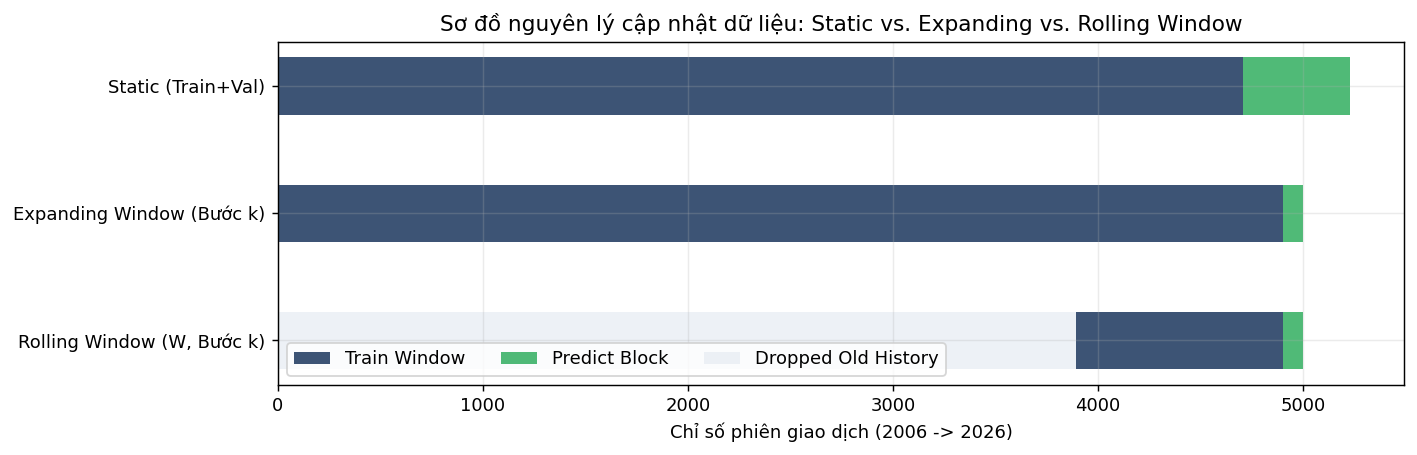

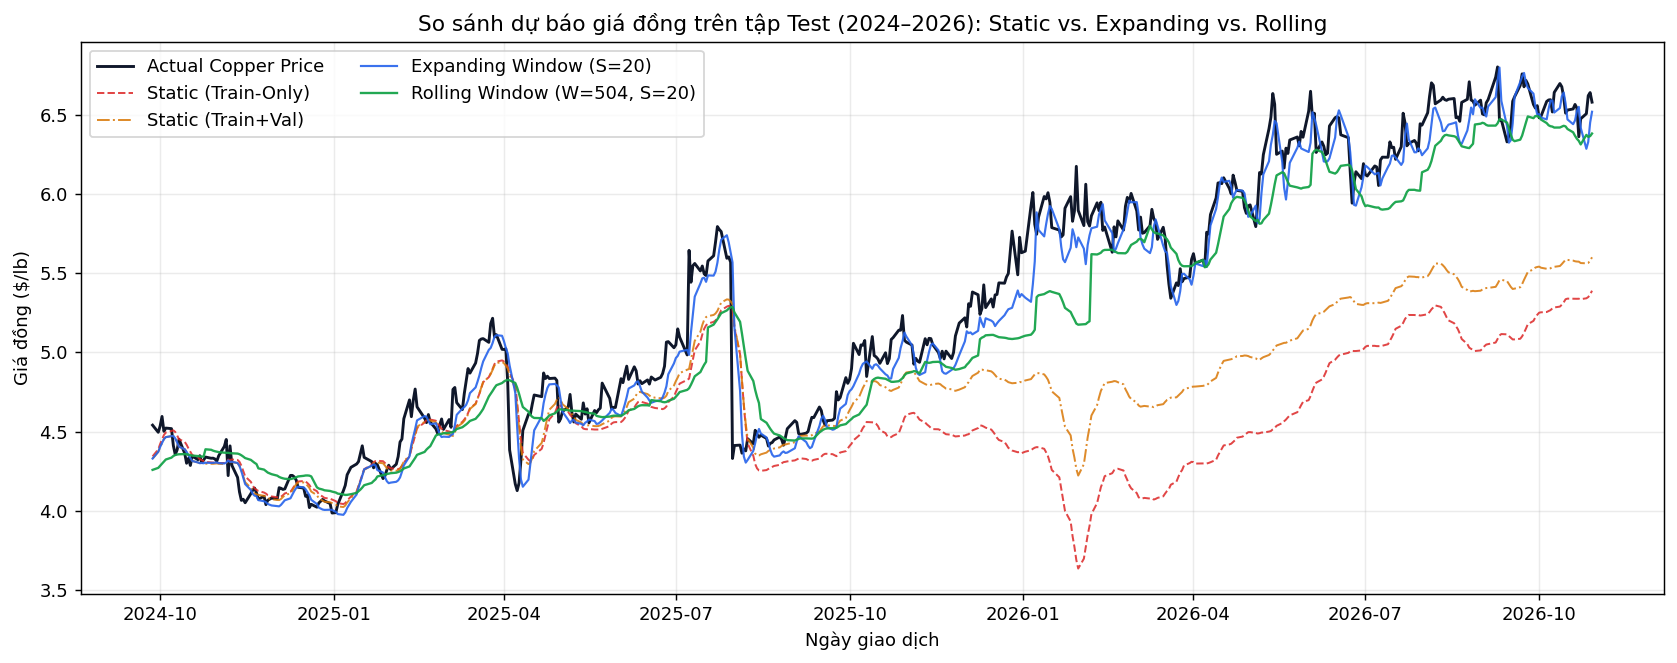

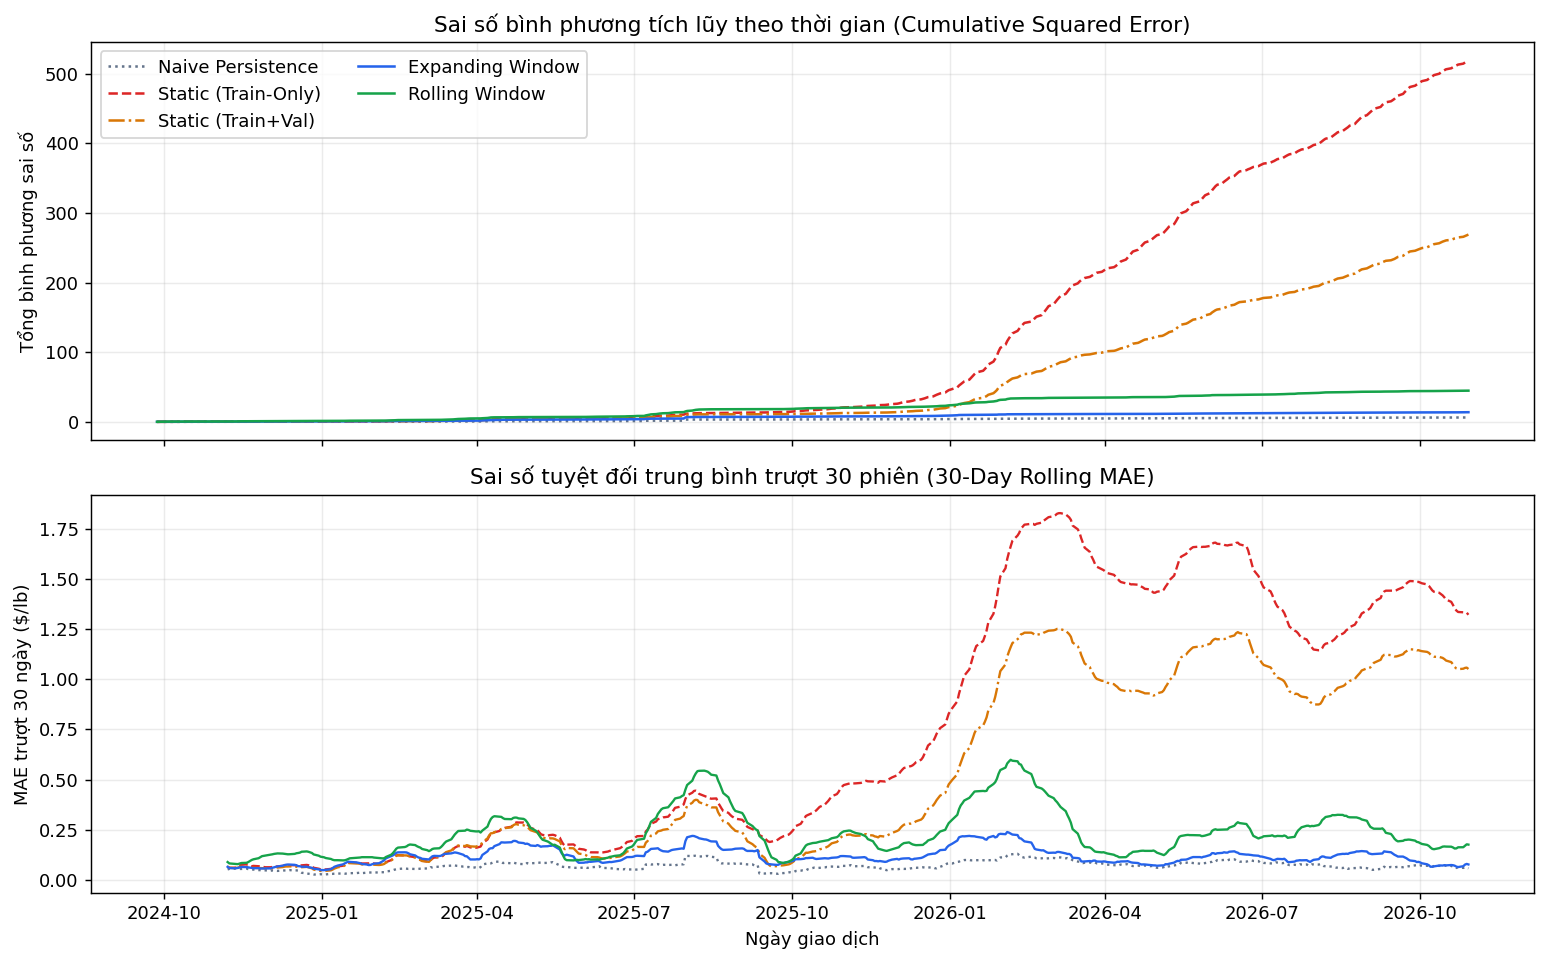

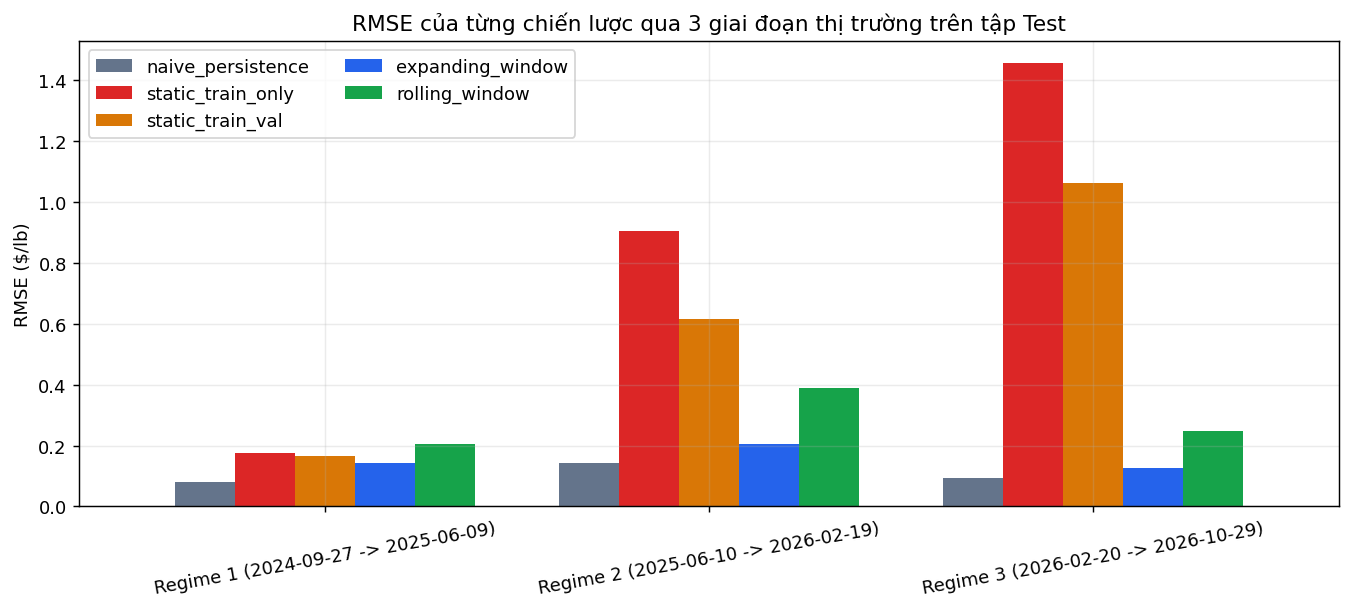

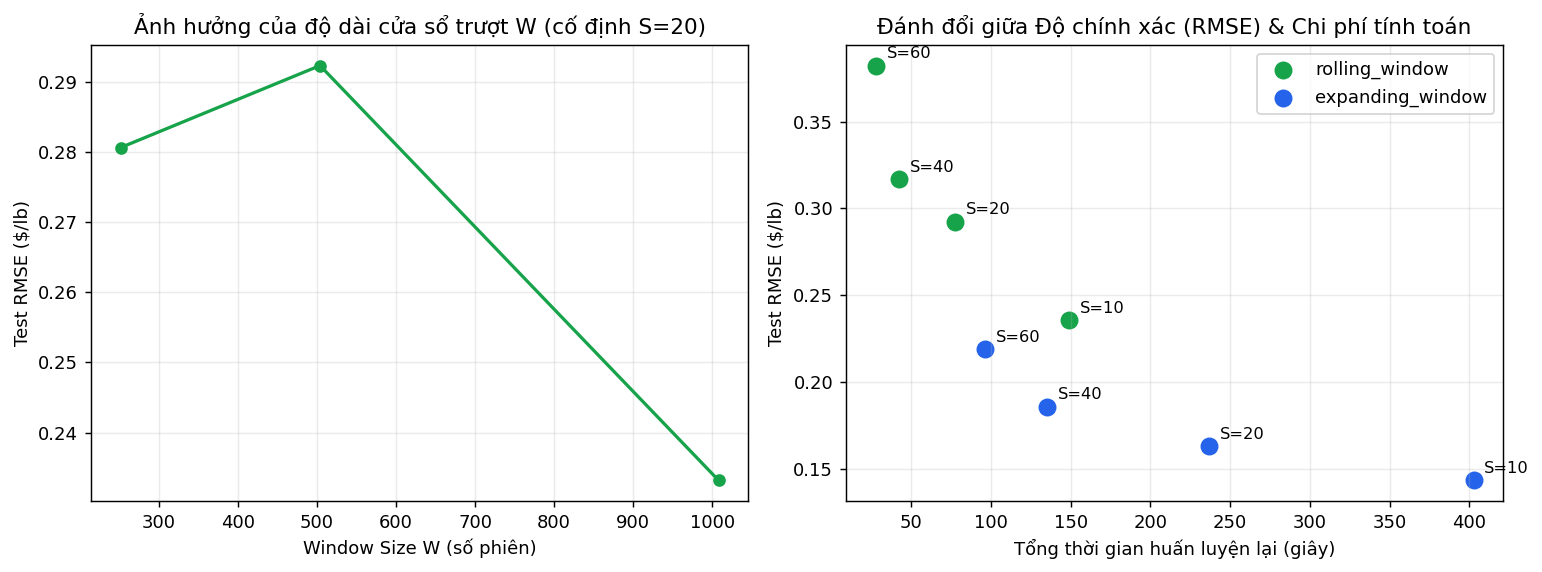

In [11]:
# Fig 2: Sơ đồ minh họa cơ chế Static / Expanding / Rolling
fig, ax = plt.subplots(figsize=(11, 3.6))
y_positions = [3, 2, 1]
labels = ["Static (Train+Val)", "Expanding Window (Bước k)", "Rolling Window (W, Bước k)"]
ax.barh(3, 4707, left=0, height=0.45, color="#1B365D", alpha=0.85, label="Train Window")
ax.barh(3, 524, left=4707, height=0.45, color="#16A34A", alpha=0.75, label="Predict Block")

ax.barh(2, 4900, left=0, height=0.45, color="#1B365D", alpha=0.85)
ax.barh(2, 100, left=4900, height=0.45, color="#16A34A", alpha=0.75)

ax.barh(1, 1008, left=3892, height=0.45, color="#1B365D", alpha=0.85)
ax.barh(1, 3892, left=0, height=0.45, color="#E2E8F0", alpha=0.6, label="Dropped Old History")
ax.barh(1, 100, left=4900, height=0.45, color="#16A34A", alpha=0.75)

ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.set_xlabel("Chỉ số phiên giao dịch (2006 -> 2026)")
ax.set_title("Sơ đồ nguyên lý cập nhật dữ liệu: Static vs. Expanding vs. Rolling Window")
ax.legend(loc="lower left", ncol=3)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig2_walkforward_schematic.png", dpi=150)
plt.show()

# Fig 3: Actual vs Predicted trên tập Test
fig, ax = plt.subplots(figsize=(13, 5.2))
df_roll = test_predictions["FEATURES_4__rolling_window"]
df_exp = test_predictions["FEATURES_4__expanding_window"]
df_stat = test_predictions["FEATURES_4__static_train_only"]
df_stv = test_predictions["FEATURES_4__static_train_val"]

dates_t = pd.to_datetime(df_roll["Date"])
ax.plot(dates_t, df_roll["actual"], color="#0F172A", linewidth=1.6, label="Actual Copper Price")
ax.plot(dates_t, df_stat["predicted"], color="#DC2626", linewidth=1.1, linestyle="--", alpha=0.85, label="Static (Train-Only)")
ax.plot(dates_t, df_stv["predicted"], color="#D97706", linewidth=1.1, linestyle="-.", alpha=0.85, label="Static (Train+Val)")
ax.plot(dates_t, df_exp["predicted"], color="#2563EB", linewidth=1.2, alpha=0.9, label=f"Expanding Window (S={BEST_S})")
ax.plot(dates_t, df_roll["predicted"], color="#16A34A", linewidth=1.3, alpha=0.95, label=f"Rolling Window (W={BEST_W}, S={BEST_S})")
ax.set_title("So sánh dự báo giá đồng trên tập Test (2024–2026): Static vs. Expanding vs. Rolling")
ax.set_ylabel("Giá đồng ($/lb)")
ax.set_xlabel("Ngày giao dịch")
ax.legend(loc="best", ncol=2)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig3_actual_vs_predicted.png", dpi=150)
plt.show()

# Fig 4: Cumulative Squared Error (CSE) & Fig 5: Rolling 30-day MAE
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
styles = [
    ("FEATURES_4__naive_persistence", "Naive Persistence", "#64748B", ":"),
    ("FEATURES_4__static_train_only", "Static (Train-Only)", "#DC2626", "--"),
    ("FEATURES_4__static_train_val", "Static (Train+Val)", "#D97706", "-."),
    ("FEATURES_4__expanding_window", "Expanding Window", "#2563EB", "-"),
    ("FEATURES_4__rolling_window", "Rolling Window", "#16A34A", "-"),
]
for key, name, col, ls in styles:
    d = test_predictions[key]
    axes[0].plot(dates_t, d["sq_error"].cumsum(), label=name, color=col, linestyle=ls, linewidth=1.4)
    axes[1].plot(dates_t, d["abs_error"].rolling(30).mean(), label=name, color=col, linestyle=ls, linewidth=1.3)

axes[0].set_title("Sai số bình phương tích lũy theo thời gian (Cumulative Squared Error)")
axes[0].set_ylabel("Tổng bình phương sai số")
axes[0].legend(loc="upper left", ncol=2)

axes[1].set_title("Sai số tuyệt đối trung bình trượt 30 phiên (30-Day Rolling MAE)")
axes[1].set_ylabel("MAE trượt 30 ngày ($/lb)")
axes[1].set_xlabel("Ngày giao dịch")
plt.tight_layout()
fig.savefig(OUT_DIR / "fig4_5_cumulative_and_rolling_errors.png", dpi=150)
plt.show()

# Fig 6: Regime Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10.5, 4.8))
pivot_reg = regime_df.pivot(index="regime", columns="strategy", values="RMSE")[
    ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]
]
pivot_reg.plot(kind="bar", ax=ax, width=0.78, color=["#64748B", "#DC2626", "#D97706", "#2563EB", "#16A34A"])
ax.set_title("RMSE của từng chiến lược qua 3 giai đoạn thị trường trên tập Test")
ax.set_ylabel("RMSE ($/lb)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=10)
ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig6_regime_comparison_bar.png", dpi=150)
plt.show()

# Fig 7: Ablation Trade-off (Accuracy vs Retraining Cost)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ab_w = ablation_df[ablation_df["ablation_type"] == "window_size"]
axes[0].plot(ab_w["window_size"].astype(int), ab_w["RMSE"], marker="o", color="#16A34A", linewidth=1.8, label="RMSE")
axes[0].set_title(f"Ảnh hưởng của độ dài cửa sổ trượt W (cố định S={BEST_S})")
axes[0].set_xlabel("Window Size W (số phiên)")
axes[0].set_ylabel("Test RMSE ($/lb)")

ab_s = ablation_df[ablation_df["ablation_type"] == "retrain_stride"]
for strat, col in [("rolling_window", "#16A34A"), ("expanding_window", "#2563EB")]:
    sub = ab_s[ab_s["strategy"] == strat]
    axes[1].scatter(sub["total_train_sec"], sub["RMSE"], s=80, color=col, label=strat)
    for _, r in sub.iterrows():
        axes[1].annotate(f"S={int(r['stride'])}", (r["total_train_sec"], r["RMSE"]),
                         textcoords="offset points", xytext=(6, 4), fontsize=9)
axes[1].set_title("Đánh đổi giữa Độ chính xác (RMSE) & Chi phí tính toán")
axes[1].set_xlabel("Tổng thời gian huấn luyện lại (giây)")
axes[1].set_ylabel("Test RMSE ($/lb)")
axes[1].legend()
plt.tight_layout()
fig.savefig(OUT_DIR / "fig7_ablation_tradeoff.png", dpi=150)
plt.show()

## 14. Tổng hợp báo cáo tự động phục vụ viết bài báo cáo nhóm

Sinh tự động file `rolling_expanding_summary_report.md` chứa các bảng số liệu đo thực tế từ phiên chạy này (tuyệt đối không nội suy) để nhóm ghép trực tiếp vào báo cáo tổng kết.

In [12]:
def generate_summary_report(out_dir: Path):
    f4 = main_test_df[main_test_df["feature_set"] == "FEATURES_4"].set_index("strategy")
    lines = [
        "# Báo cáo thực nghiệm Phương pháp 4: Rolling & Expanding Window Forecasting",
        "",
        f"- **Chế độ chạy:** `{MODE}` | **Dữ liệu:** {len(data)} phiên ({data.index.min().date()} -> {data.index.max().date()})",
        f"- **Chính sách Walk-Forward chọn từ Validation:** `W* = {BEST_W}` phiên, `S* = {BEST_S}` phiên, `update_mode* = {BEST_UPDATE_MODE}`",
        f"- **Kiến trúc cơ sở cố định:** 2-layer LSTM ({ACTIVE_HP}), Lookback = {LOOKBACK}, Horizon = {HORIZON}",
        "",
        "## 1. Bảng kết quả chính trên tập Test (FEATURES_4: Copper, WTI, Gold, Silver)",
        "",
        "| Chiến lược | MAE ($/lb) | RMSE ($/lb) | MASE | R² | Số lần Retrain | Thời gian (s) |",
        "|---|---:|---:|---:|---:|---:|---:|",
    ]
    for strat in ["naive_persistence", "static_train_only", "static_train_val", "expanding_window", "rolling_window"]:
        r = f4.loc[strat]
        lines.append(
            f"| {strat} | {r['MAE']:.4f} | {r['RMSE']:.4f} | {r['MASE']:.4f} | {r['R2']:.4f} | {int(r['n_retrains'])} | {r['total_train_sec']:.1f} |"
        )

    roll_rmse = float(f4.loc["rolling_window", "RMSE"])
    stat_rmse = float(f4.loc["static_train_only", "RMSE"])
    stv_rmse = float(f4.loc["static_train_val", "RMSE"])
    exp_rmse = float(f4.loc["expanding_window", "RMSE"])

    lines += [
        "",
        "## 2. So sánh cải thiện tương đối (RMSE)",
        f"- Rolling Window vs. Static (Train-Only): **{(roll_rmse / stat_rmse - 1) * 100:+.2f}%**",
        f"- Rolling Window vs. Static (Train+Val): **{(roll_rmse / stv_rmse - 1) * 100:+.2f}%**",
        f"- Expanding Window vs. Static (Train-Only): **{(exp_rmse / stat_rmse - 1) * 100:+.2f}%**",
        f"- Rolling Window vs. Expanding Window: **{(roll_rmse / exp_rmse - 1) * 100:+.2f}%**",
        "",
        "## 3. Kiểm định ý nghĩa thống kê Diebold-Mariano (DM Test)",
        "",
        "| So sánh | Loss | DM Stat | p-value | Có ý nghĩa (5%) |",
        "|---|---|---:|---:|:---:|",
    ]
    for _, row in dm_df.iterrows():
        sig = "Có" if row["significant_5pct"] else "Không"
        lines.append(f"| {row['comparison']} | {row['loss']} | {row['DM_stat']:.3f} | {row['p_value']:.4f} | {sig} |")

    report_text = "\n".join(lines)
    (out_dir / "rolling_expanding_summary_report.md").write_text(report_text, encoding="utf-8")
    return report_text

report_md = generate_summary_report(OUT_DIR)
display(Markdown(report_md))
print(f"\nHoàn tất! Toàn bộ bảng CSV, biểu đồ PNG và báo cáo MD đã được lưu tại: {OUT_DIR}")

# Báo cáo thực nghiệm Phương pháp 4: Rolling & Expanding Window Forecasting

- **Chế độ chạy:** `FULL_RESEARCH_MODE` | **Dữ liệu:** 5231 phiên (2006-01-03 -> 2026-10-29)
- **Chính sách Walk-Forward chọn từ Validation:** `W* = 504` phiên, `S* = 20` phiên, `update_mode* = warm_start`
- **Kiến trúc cơ sở cố định:** 2-layer LSTM ({'lstm_units_1': 9, 'lstm_units_2': 37, 'learning_rate': 0.00040267575055105107}), Lookback = 22, Horizon = 1

## 1. Bảng kết quả chính trên tập Test (FEATURES_4: Copper, WTI, Gold, Silver)

| Chiến lược | MAE ($/lb) | RMSE ($/lb) | MASE | R² | Số lần Retrain | Thời gian (s) |
|---|---:|---:|---:|---:|---:|---:|
| naive_persistence | 0.0693 | 0.1092 | 1.7593 | 0.9827 | 0 | 0.0 |
| static_train_only | 0.7563 | 0.9953 | 19.3730 | -0.4356 | 1 | 31.7 |
| static_train_val | 0.5393 | 0.7165 | 13.6871 | 0.2562 | 1 | 35.0 |
| expanding_window | 0.1172 | 0.1625 | 2.9759 | 0.9617 | 27 | 236.1 |
| rolling_window | 0.2259 | 0.2923 | 5.7325 | 0.8762 | 27 | 77.4 |

## 2. So sánh cải thiện tương đối (RMSE)
- Rolling Window vs. Static (Train-Only): **-70.63%**
- Rolling Window vs. Static (Train+Val): **-59.20%**
- Expanding Window vs. Static (Train-Only): **-83.67%**
- Rolling Window vs. Expanding Window: **+79.88%**

## 3. Kiểm định ý nghĩa thống kê Diebold-Mariano (DM Test)

| So sánh | Loss | DM Stat | p-value | Có ý nghĩa (5%) |
|---|---|---:|---:|:---:|
| Rolling vs Static (Train-Only) | L1 | -19.868 | 0.0000 | Có |
| Rolling vs Static (Train-Only) | L2 | -17.927 | 0.0000 | Có |
| Rolling vs Static (Train+Val) | L1 | -16.476 | 0.0000 | Có |
| Rolling vs Static (Train+Val) | L2 | -16.451 | 0.0000 | Có |
| Expanding vs Static (Train-Only) | L1 | -22.882 | 0.0000 | Có |
| Expanding vs Static (Train-Only) | L2 | -18.557 | 0.0000 | Có |
| Expanding vs Static (Train+Val) | L1 | -20.914 | 0.0000 | Có |
| Expanding vs Static (Train+Val) | L2 | -17.758 | 0.0000 | Có |
| Rolling vs Expanding | L1 | 16.195 | 0.0000 | Có |
| Rolling vs Expanding | L2 | 12.258 | 0.0000 | Có |
| Rolling vs Naive Persistence | L1 | 20.406 | 0.0000 | Có |
| Rolling vs Naive Persistence | L2 | 13.122 | 0.0000 | Có |
| Rolling (4 Features) vs Rolling (3 Features) | L1 | -11.348 | 0.0000 | Có |
| Rolling (4 Features) vs Rolling (3 Features) | L2 | -10.066 | 0.0000 | Có |


Hoàn tất! Toàn bộ bảng CSV, biểu đồ PNG và báo cáo MD đã được lưu tại: /kaggle/working/rolling_expanding_quan/full_research_mode
